# **Stimulus decoding — SocialPresentation**

Pairwise SVM decoding of all 15 stimulus pairs from population neural activity.
Uses PCA for dimensionality reduction and repeated 70/30 stratified shuffle
splits for stable accuracy estimates.

- **1** — Window-averaged pairwise decoding (6x6 heatmap)
- **2** — Frame-by-frame temporal decoding for all pairs
- **3** — Pairwise decoding by region
- **4** — Raw vs kinematics-corrected comparison

> Tensors come from `processing_main_abf.ipynb`. Corrected tensor from
> `kinematics_regression.ipynb`. All decoders defined in `neural_analysis.py`.

## Section 0 : Load data

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from neural_analysis import NeuralAnalysis, set_style, STIM_ORDER
set_style(font="Arial", size=7)

# ---- EDIT ----
DATA       = "/Volumes/Akhil Data/Akhil/ProcessedData/IS-2-1L/2026-07-01"
pre_frames = 15
fs         = 15.06

X      = np.load(os.path.join(DATA, "tensor_zdff.npy"))
labels = np.load(os.path.join(DATA, "tensor_labels.npy"), allow_pickle=True)
try:
    regions = np.load(os.path.join(DATA, "neuron_regions.npy"), allow_pickle=True)
    print("regions loaded")
except FileNotFoundError:
    regions = None
    print("no region file")

# kinematics-corrected tensor (optional)
corr_path = os.path.join(DATA, "tensor_zdff_corrected.npy")
X_corr = np.load(corr_path) if os.path.exists(corr_path) else None
print("corrected tensor:", "loaded" if X_corr is not None else "not found")

na = NeuralAnalysis(X, labels, regions=regions, fs=fs, pre_frames=pre_frames)
print("tensor:", na.X.shape, "| stimuli:", sorted(set(na.labels)))

regions loaded
corrected tensor: loaded
tensor: (72, 5352, 120) | stimuli: ['3DMouse', 'Empty', 'FamFood', 'Female', 'Male', 'NewFood']


## Section 1 : Pairwise decoding — window-averaged (6×6 heatmap)

SVM decoding of all 15 unique stimulus pairs. Features = per-neuron
mean z-dff over the response window. 50 repeated 70/30 shuffle splits.
Results displayed as a symmetric 6×6 heatmap with significance stars.

In [ ]:
pw = na.decode_pairwise(window=(0, 6), n_shuffles=20)
display(pw[["stim_a", "stim_b", "accuracy", "chance", "p_value", "n_a", "n_b", "n_neurons"]])

,stim_a,stim_b,accuracy,chance,p_value,n_a,n_b,n_neurons
0,3DMouse,Empty,0.4350,0.498150,0.746269,12,12,5352
1,3DMouse,FamFood,0.5675,0.495187,0.194030,12,12,5352
2,3DMouse,Female,0.5975,0.498550,0.144279,12,12,5352
3,3DMouse,Male,0.7200,0.492300,0.019900,12,12,5352
4,3DMouse,NewFood,0.5100,0.505825,0.462687,12,12,5352
5,Empty,FamFood,0.4900,0.494287,0.527363,12,12,5352
6,Empty,Female,0.6050,0.491200,0.169154,12,12,5352
7,Empty,Male,0.6950,0.484912,0.019900,12,12,5352
8,Empty,NewFood,0.4650,0.499738,0.671642,12,12,5352
9,FamFood,Female,0.5325,0.501888,0.368159,12,12,5352


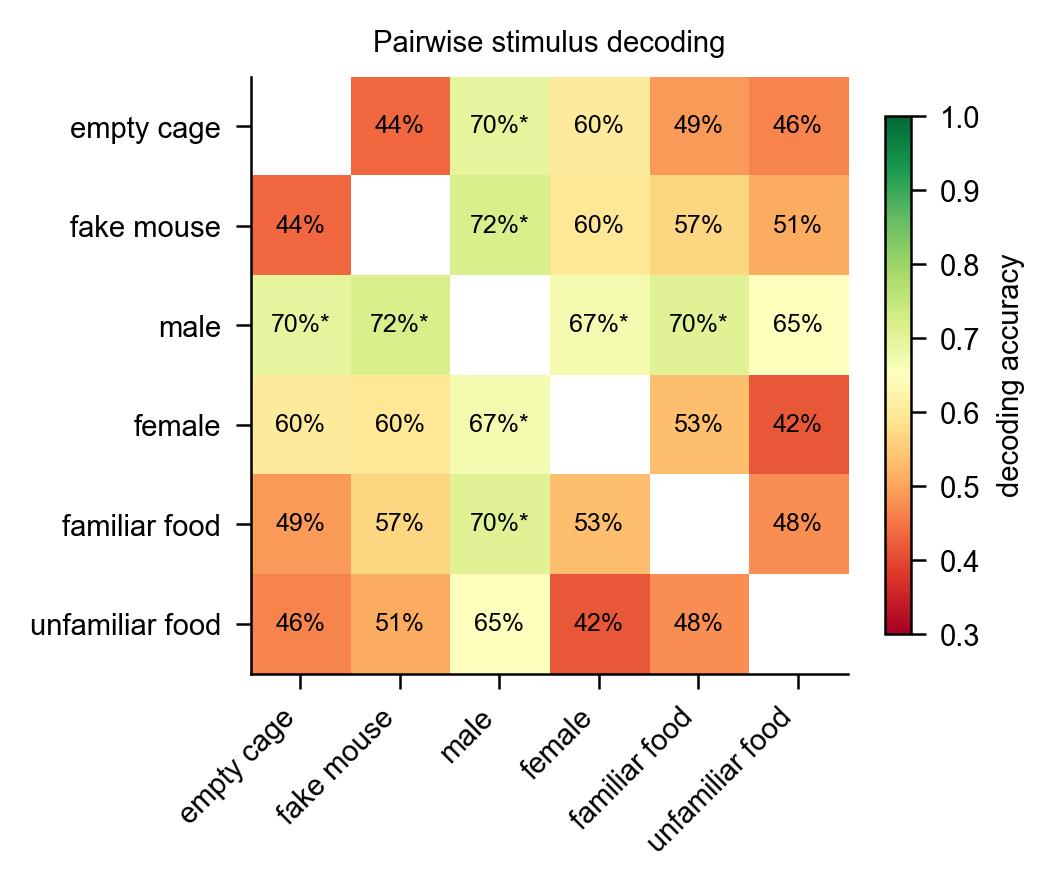

In [3]:
fig = na.plot_pairwise_matrix(pw, dpi=300)
plt.show()

## Section 2 : Frame-by-frame temporal decoding — all pairs

One SVM classifier per time point per pair. PCA to 50 components for speed.
50 repeated 70/30 stratified shuffle splits; shuffle null from 200 permutations.

In [5]:
from itertools import combinations
from scipy.ndimage import gaussian_filter1d

stims = STIM_ORDER
pairs = list(combinations(stims, 2))
temp_pw = {}
for a, b in pairs:
    name = f"{a} vs {b}"
    print(f"decoding: {name}")
    temp_pw[name] = na.decode_temporal([a], [b], n_splits=20, n_shuffles=20, n_pcs=50)
print("done — all 15 pairs")

decoding: Empty vs 3DMouse
decoding: Empty vs Male
decoding: Empty vs Female
decoding: Empty vs FamFood
decoding: Empty vs NewFood
decoding: 3DMouse vs Male
decoding: 3DMouse vs Female
decoding: 3DMouse vs FamFood
decoding: 3DMouse vs NewFood
decoding: Male vs Female
decoding: Male vs FamFood
decoding: Male vs NewFood
decoding: Female vs FamFood
decoding: Female vs NewFood
decoding: FamFood vs NewFood
done — all 15 pairs


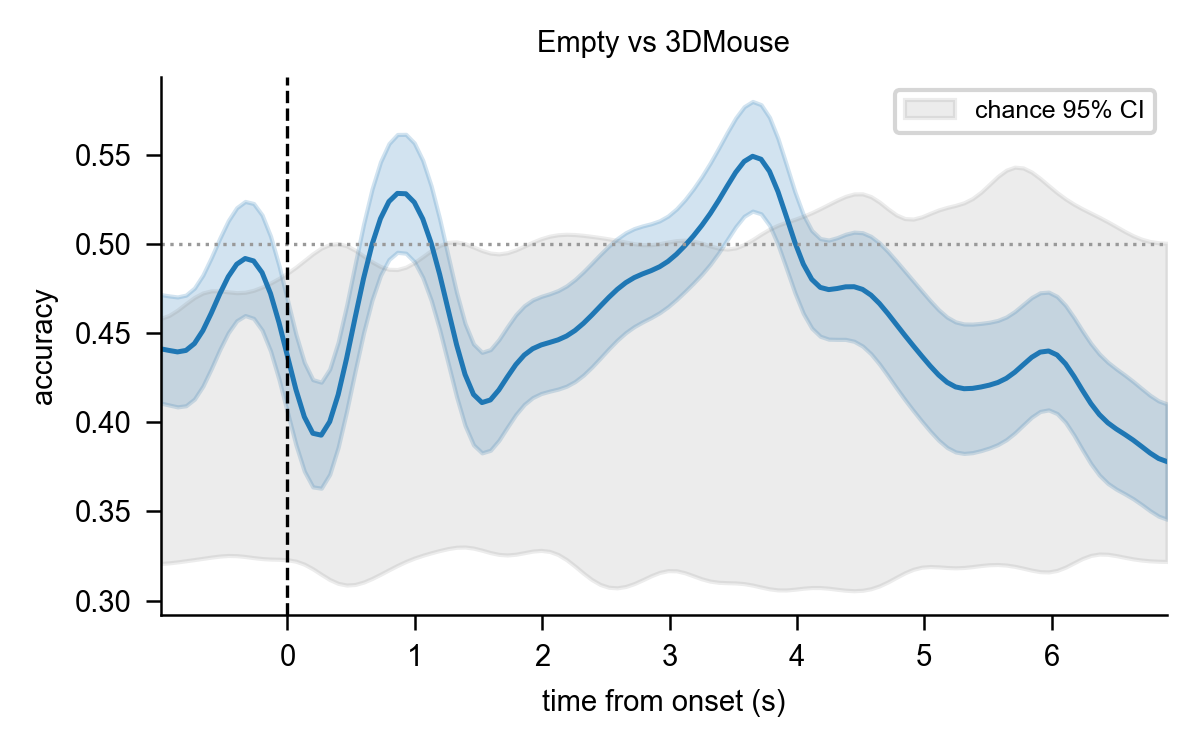

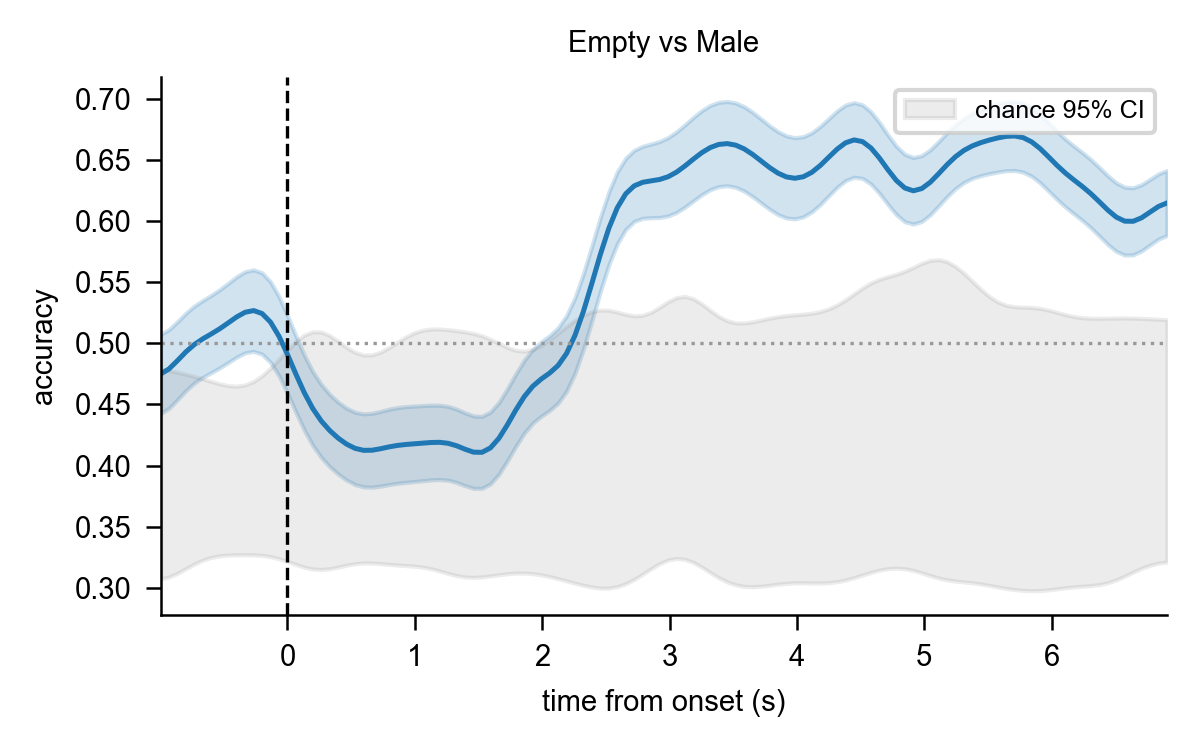

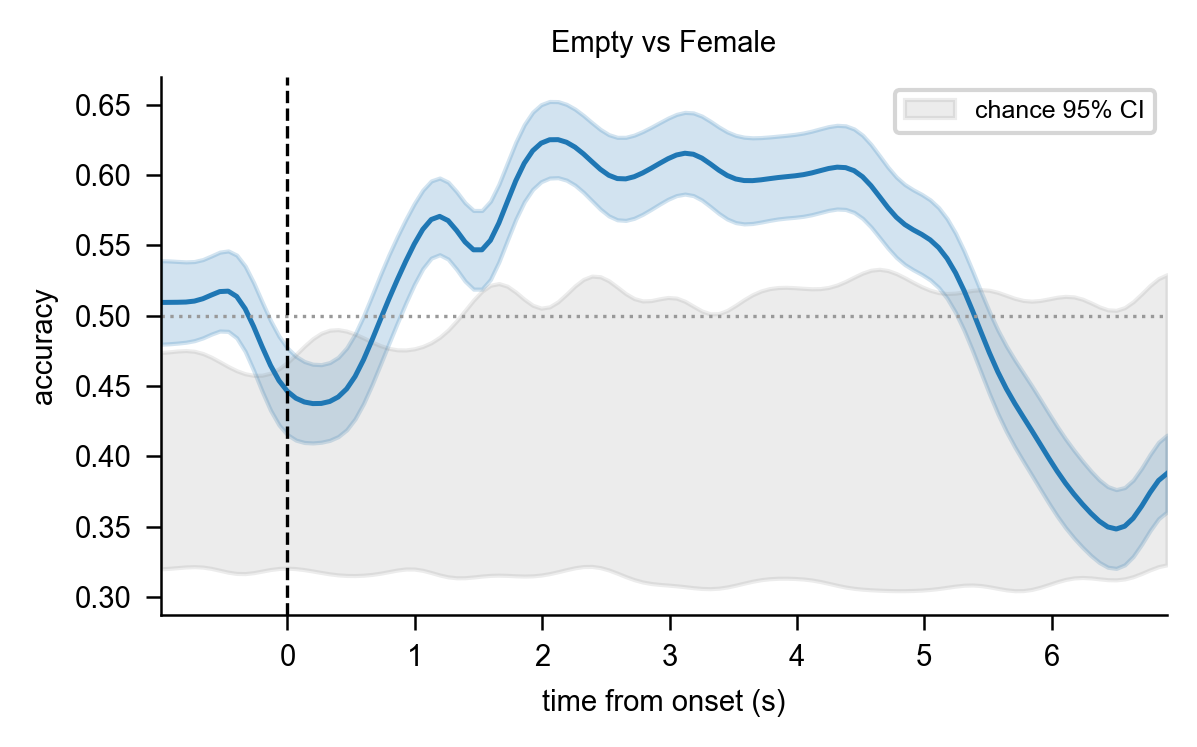

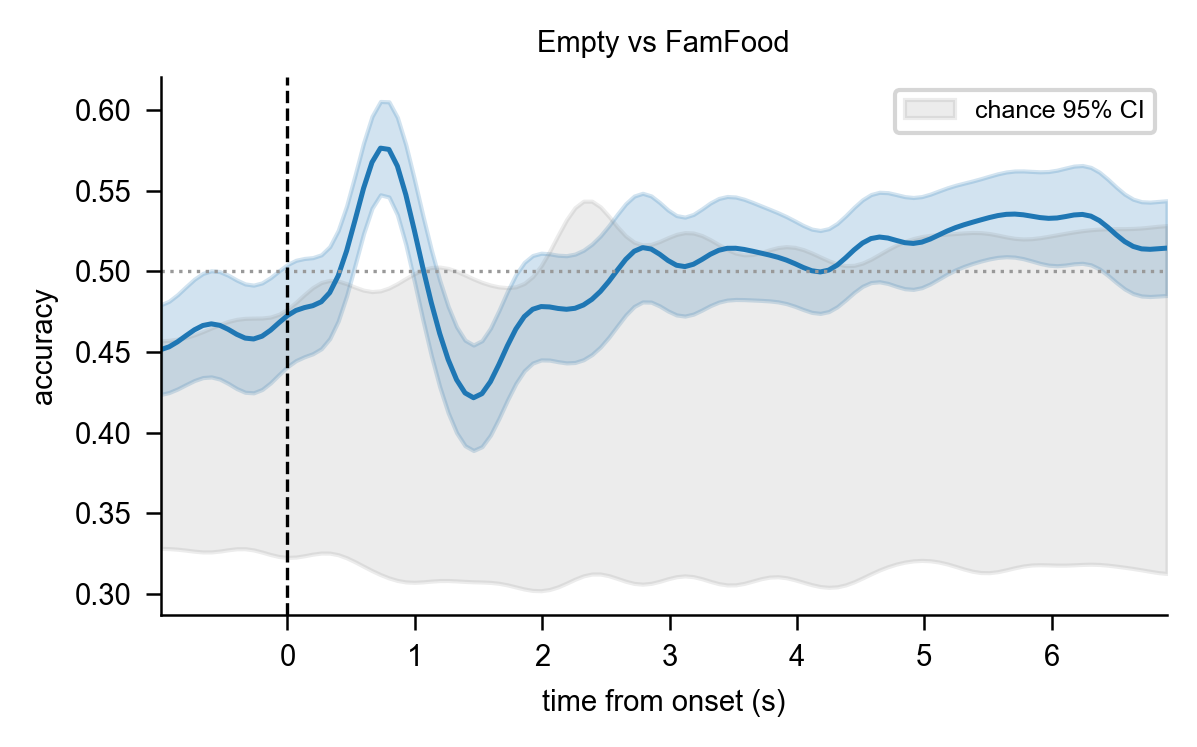

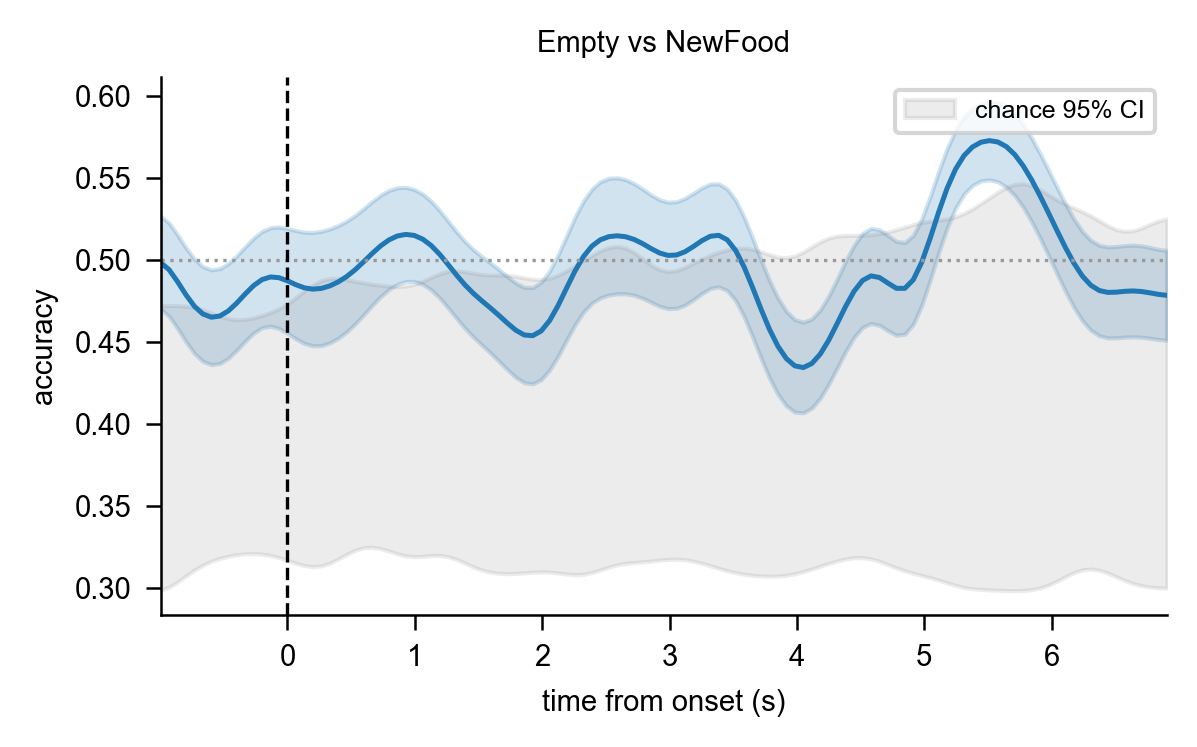

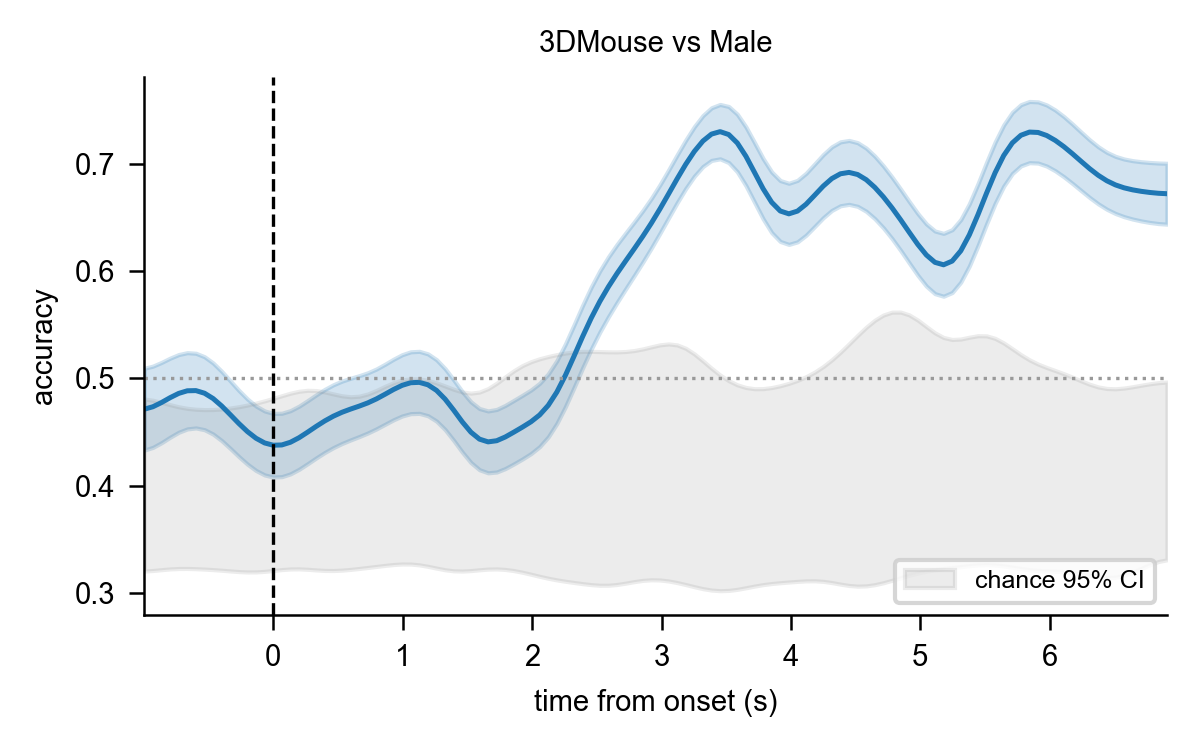

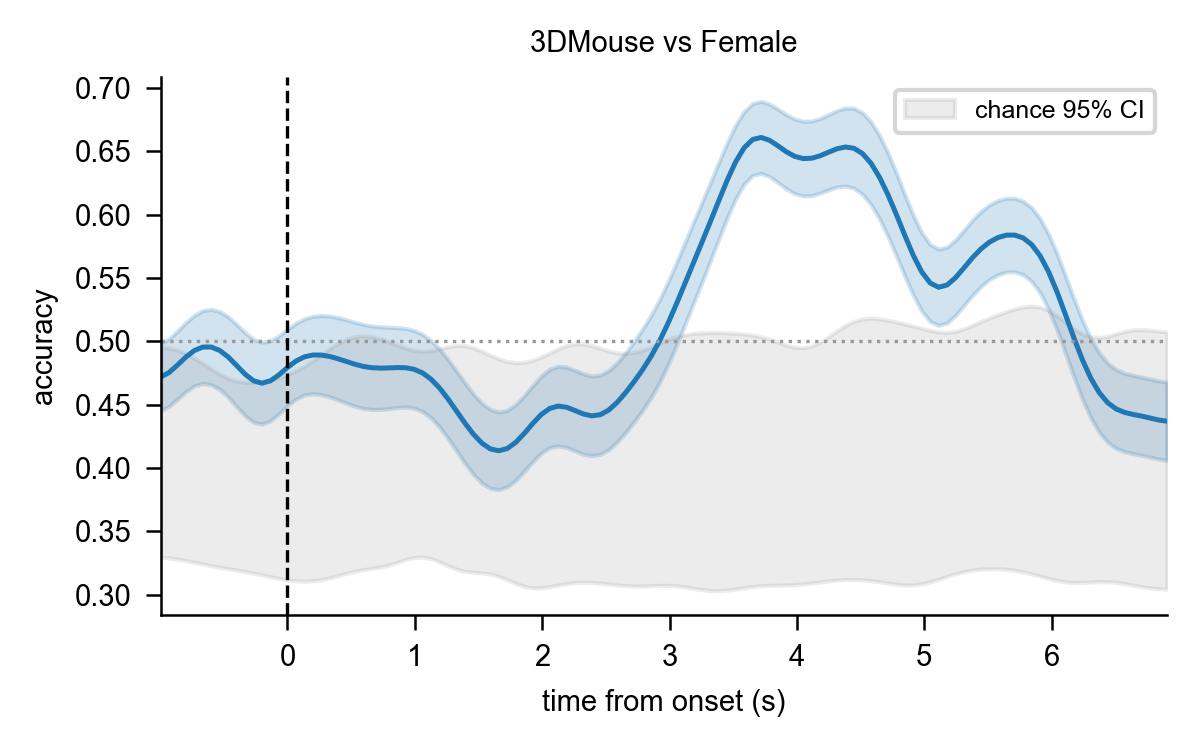

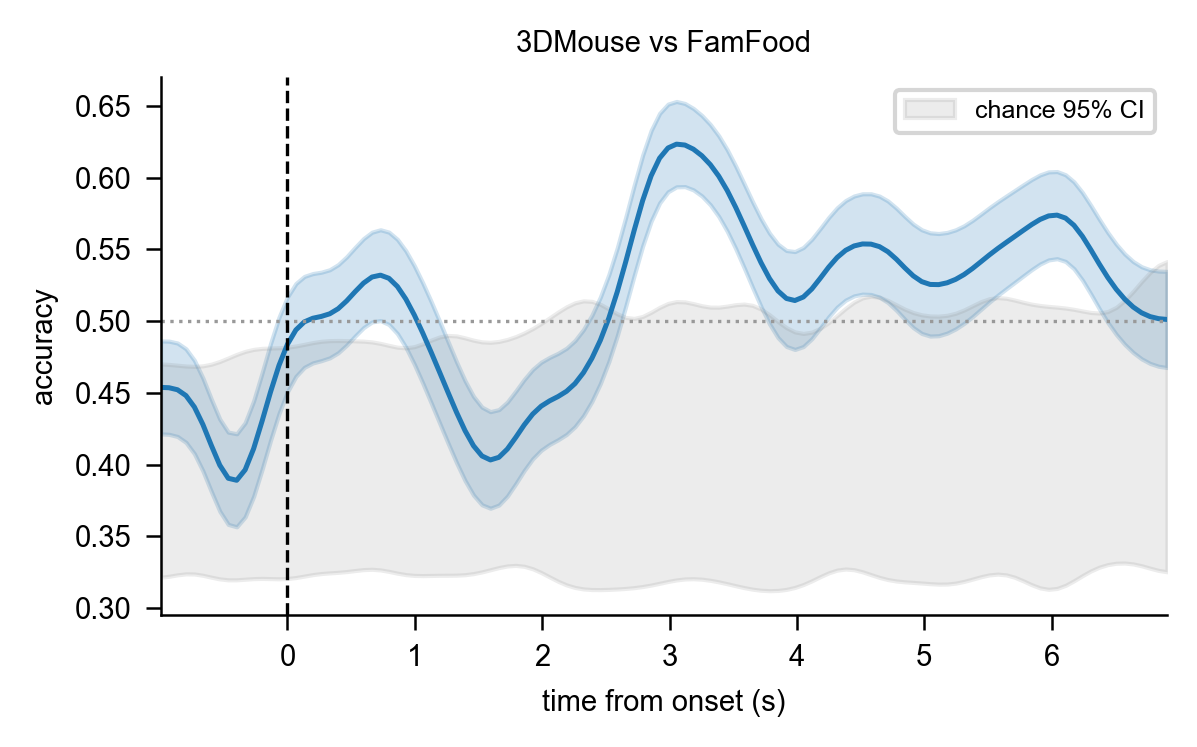

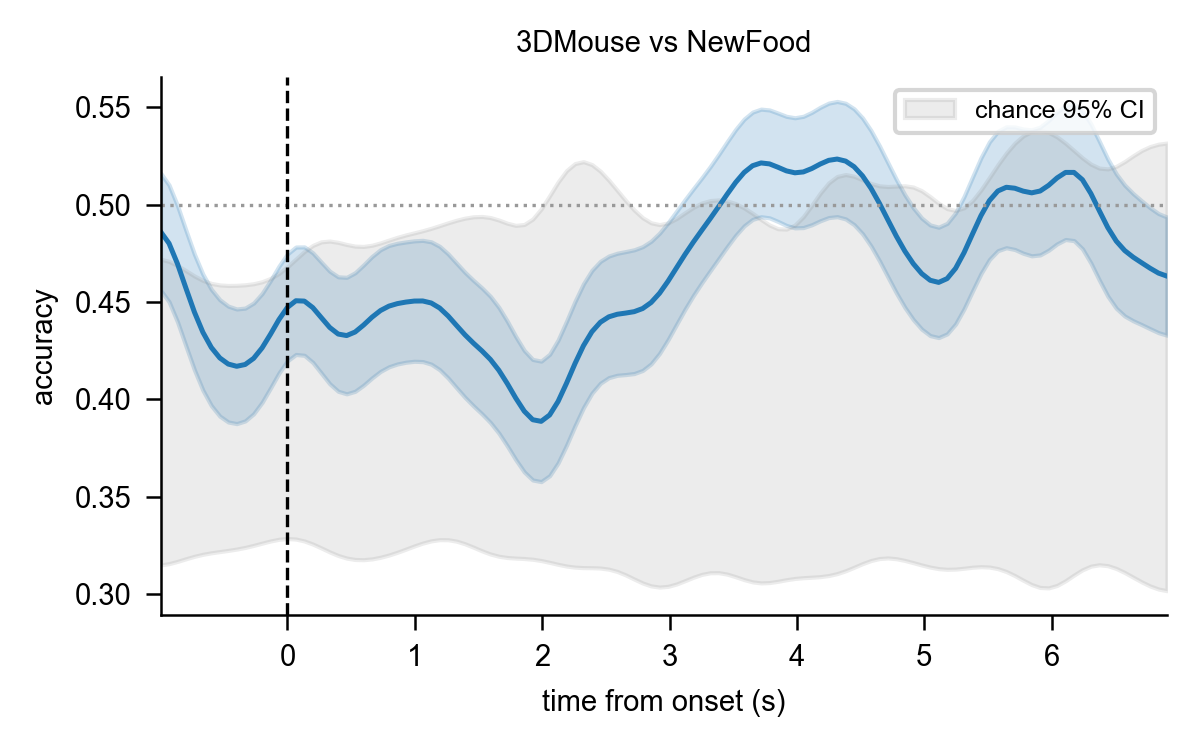

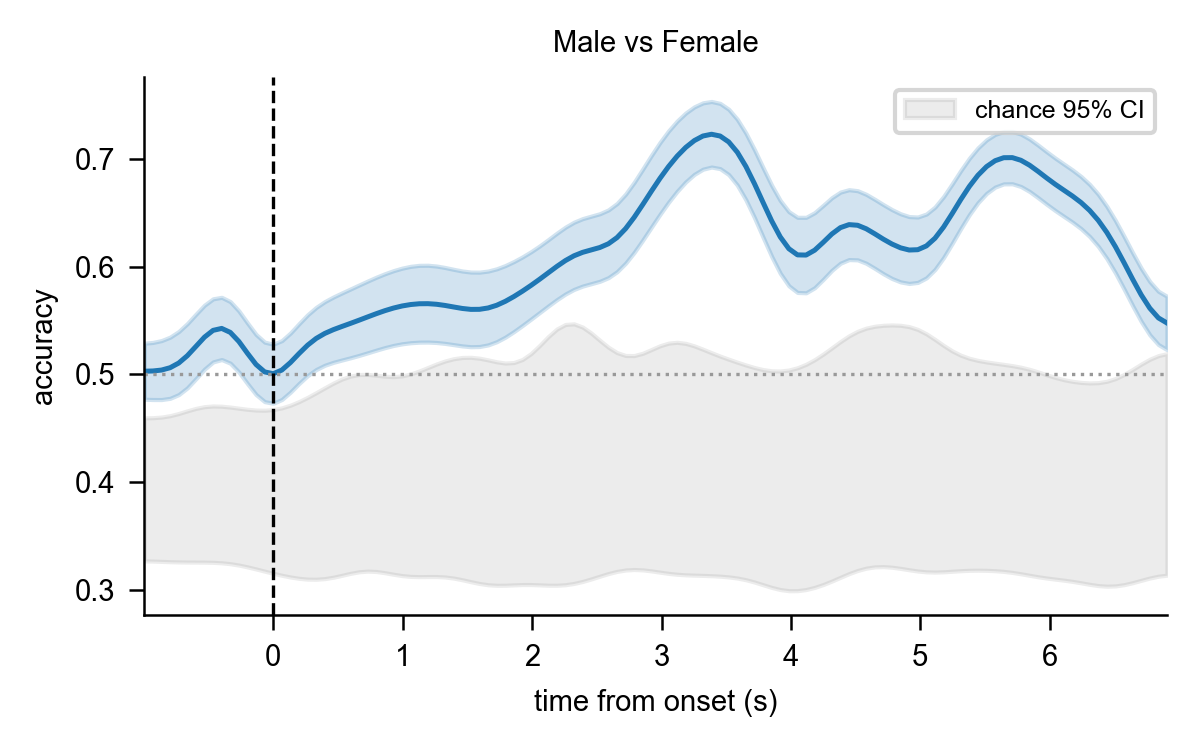

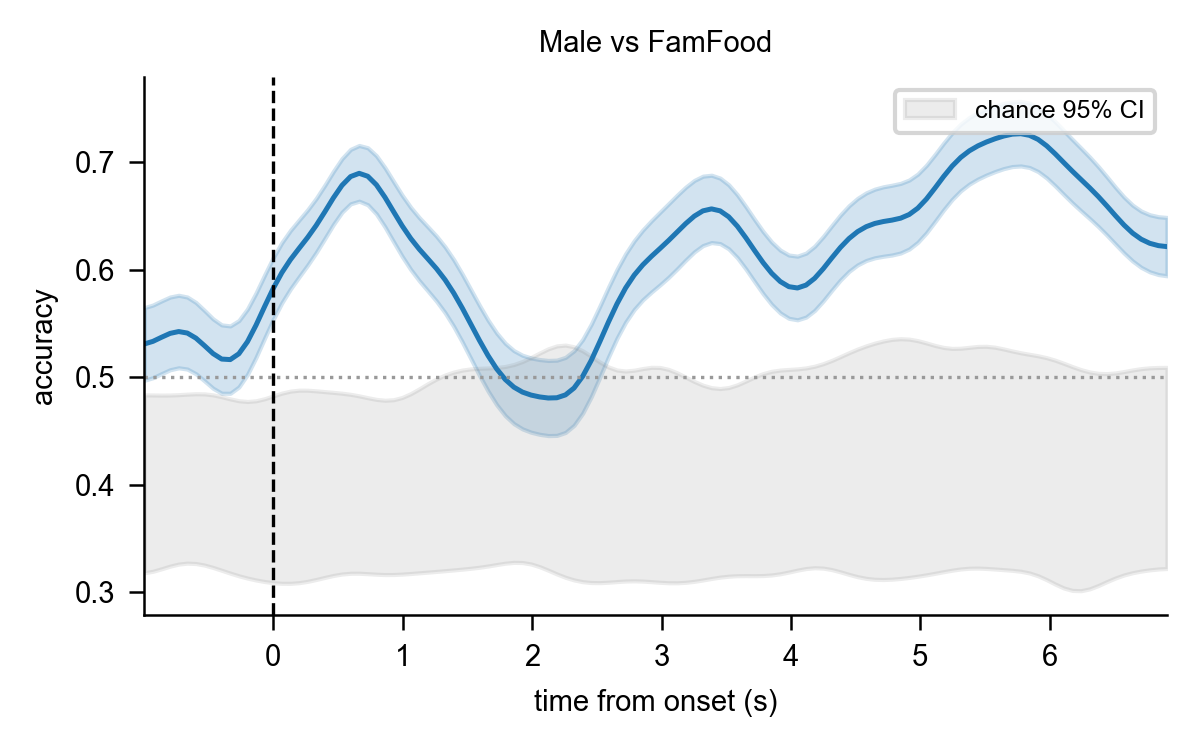

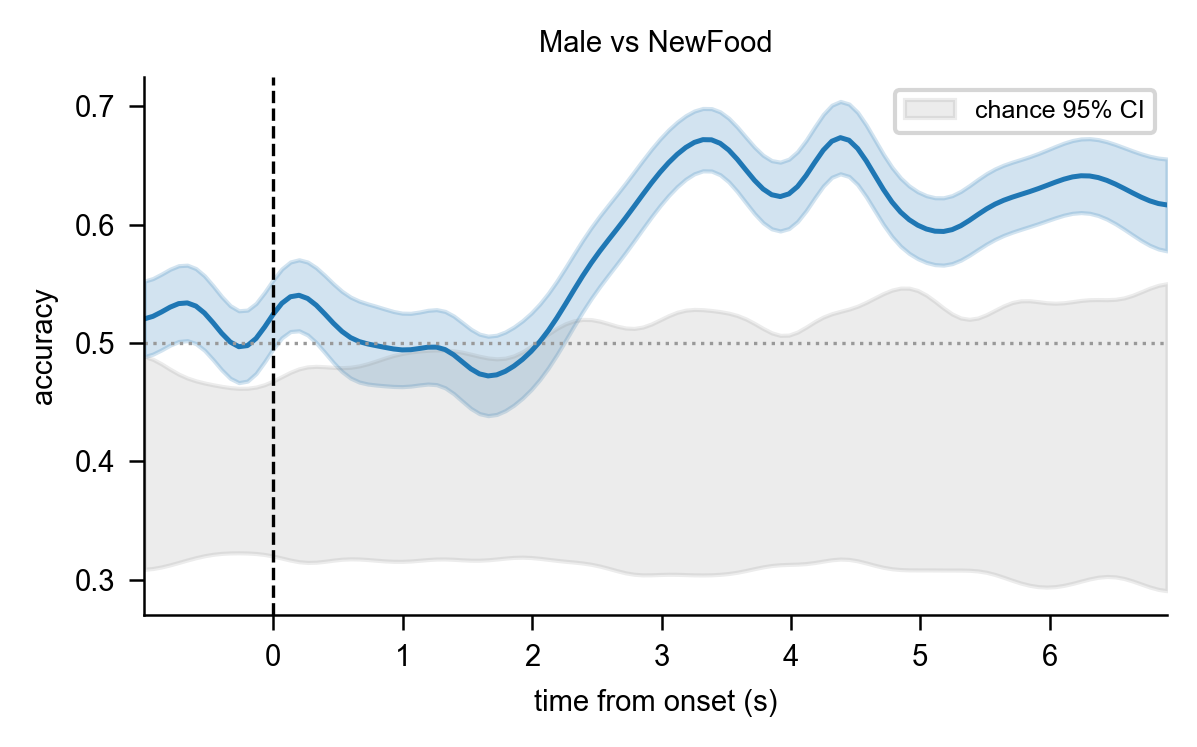

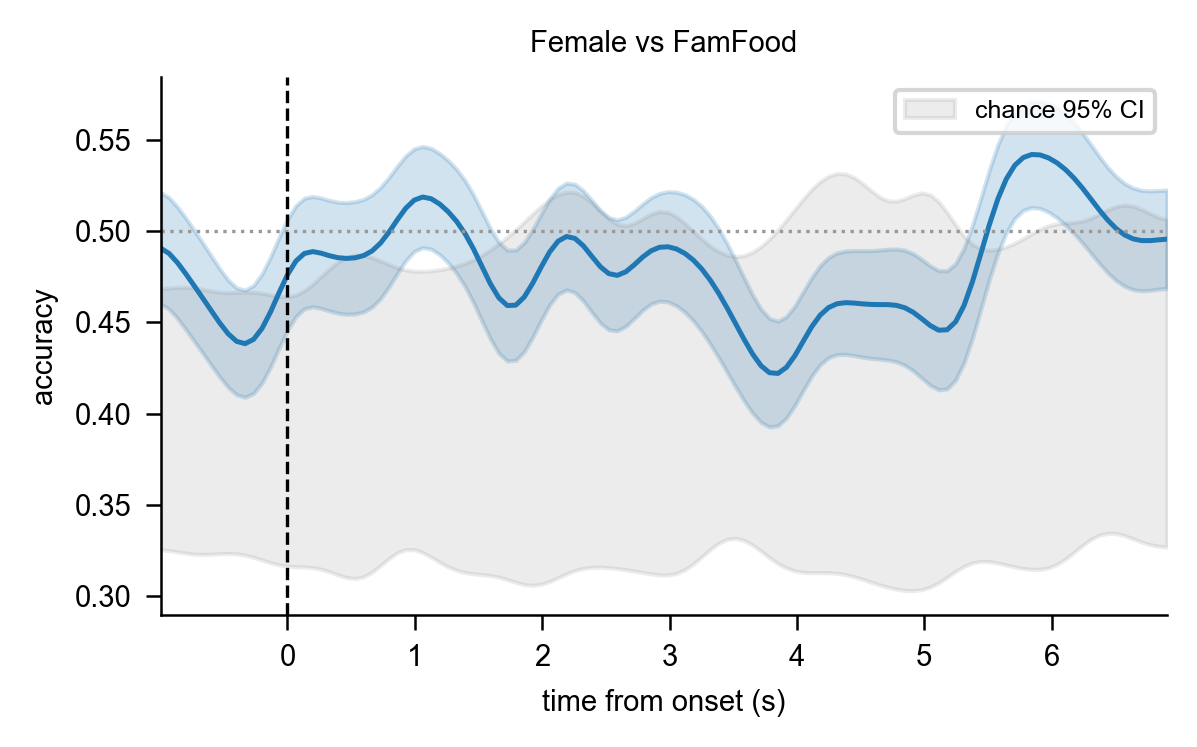

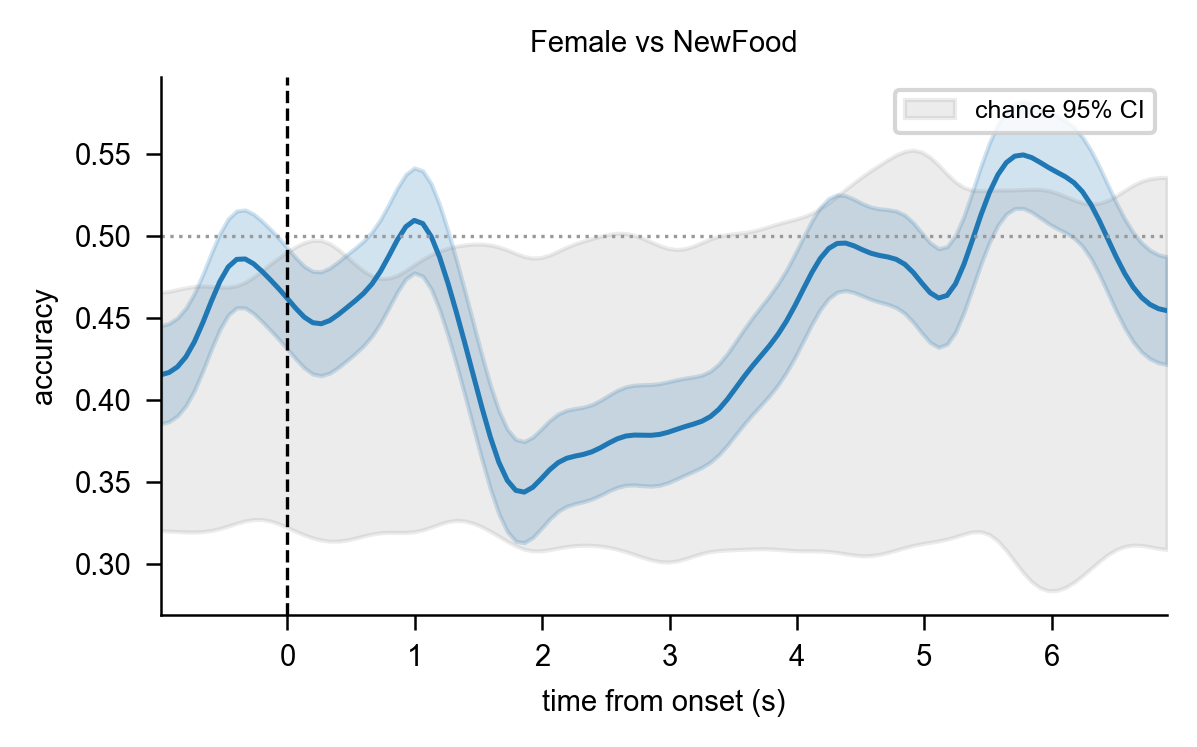

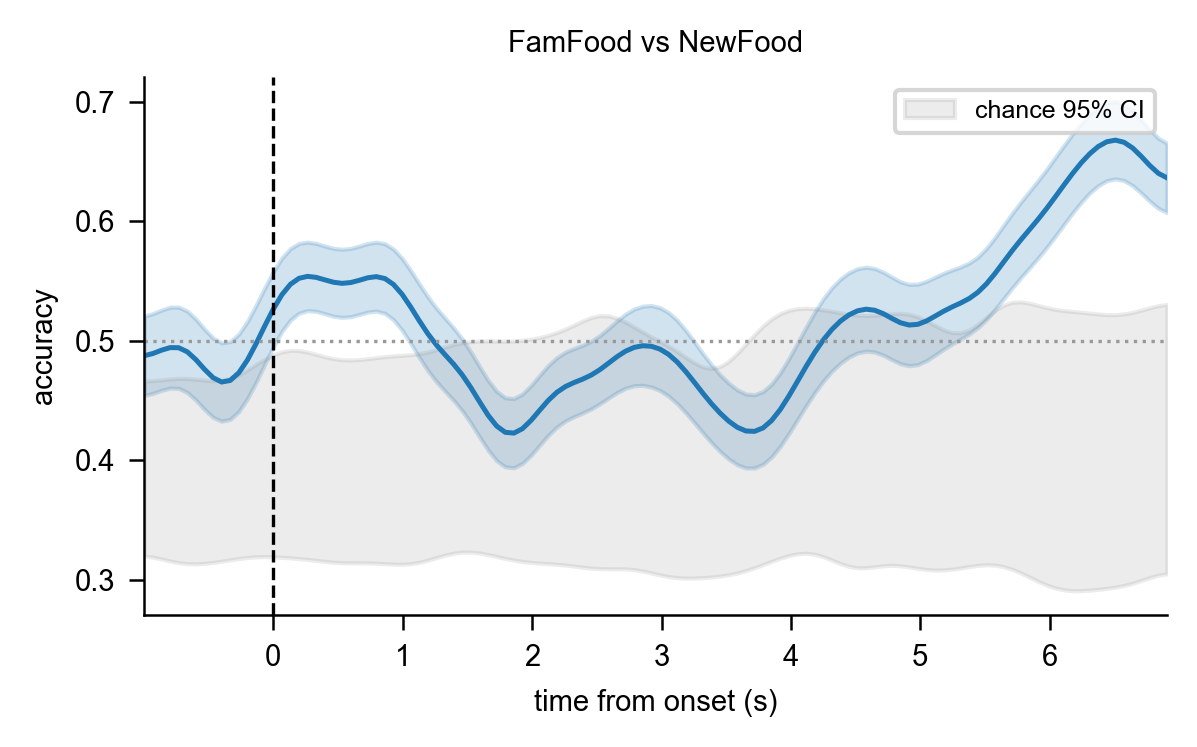

In [6]:
# plot each pair's temporal decoding
sm = lambda x: gaussian_filter1d(x, sigma=3)
for name, r in temp_pw.items():
    fig, ax = plt.subplots(figsize=(4, 2.5), dpi=300)
    t = r["time"]
    ax.plot(t, sm(r["accuracy"]), lw=1.2, color="tab:blue")
    ax.fill_between(t, sm(r["accuracy"] - r["accuracy_sem"]),
                       sm(r["accuracy"] + r["accuracy_sem"]),
                    color="tab:blue", alpha=0.2)
    ax.fill_between(t, sm(r["chance_ci"][:, 0]), sm(r["chance_ci"][:, 1]),
                    color="gray", alpha=0.15, label="chance 95% CI")
    ax.axhline(0.5, color="0.6", ls=":", lw=0.8)
    ax.axvline(0, color="k", ls="--", lw=0.8)
    ax.set(xlabel="time from onset (s)", ylabel="accuracy", title=name,
           xlim=(t[0], t[-1]))
    ax.legend(fontsize=6)
    fig.tight_layout()
    plt.show()

## Section 3 : Pairwise decoding by region

One 6×6 heatmap per cortical region. Window-averaged features, same SVM setup.

--- AM ---


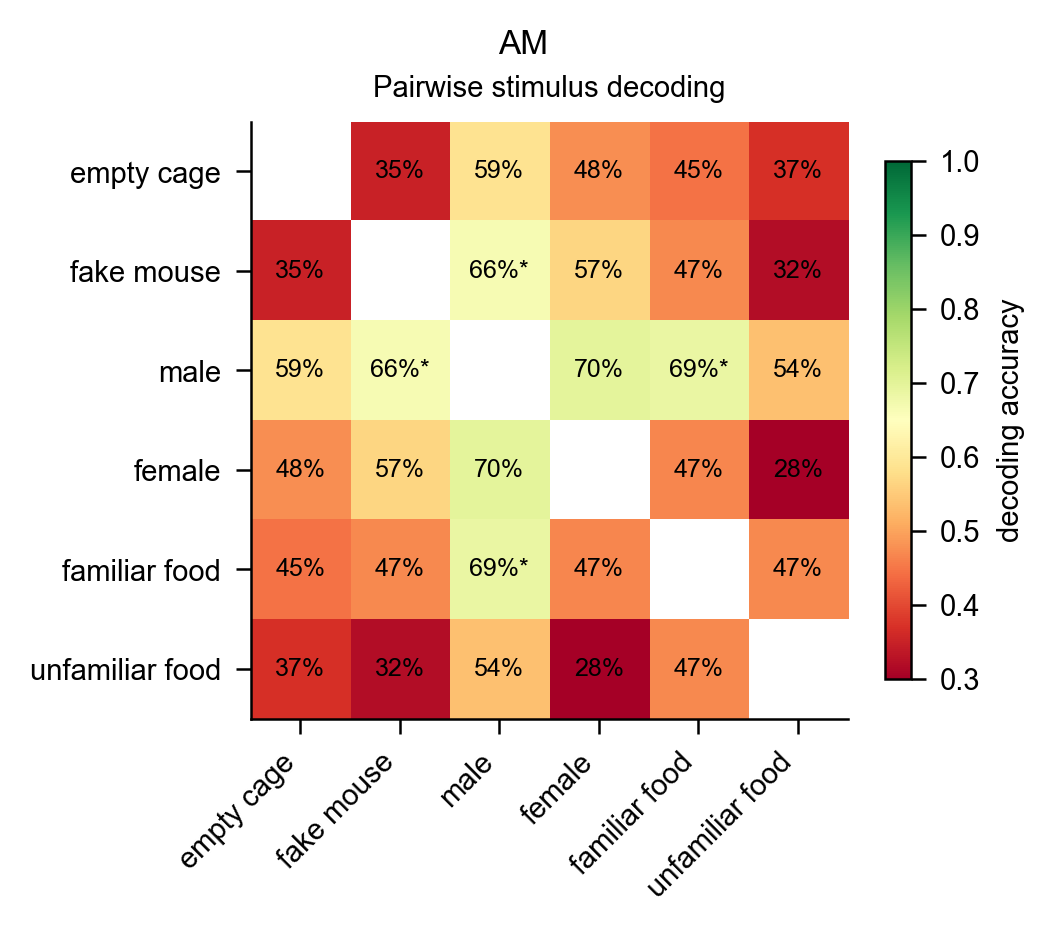

--- PM ---


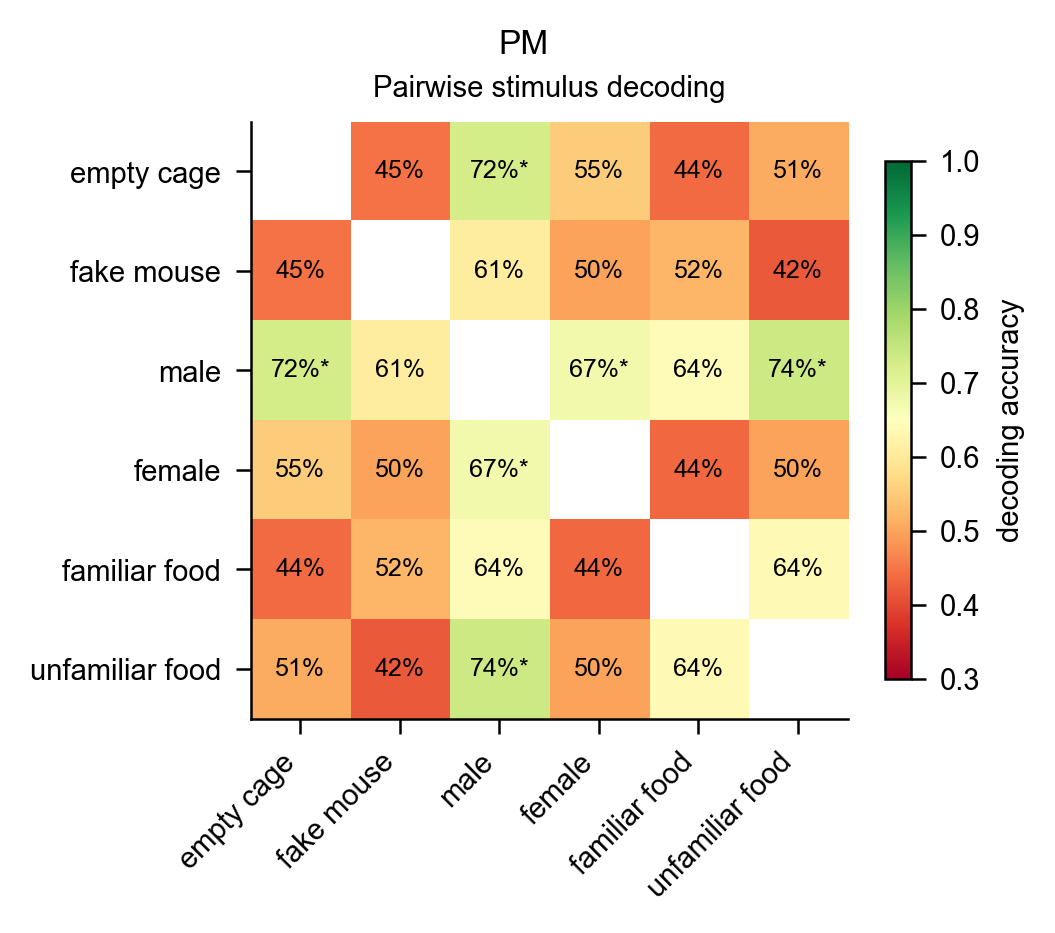

--- PPC ---


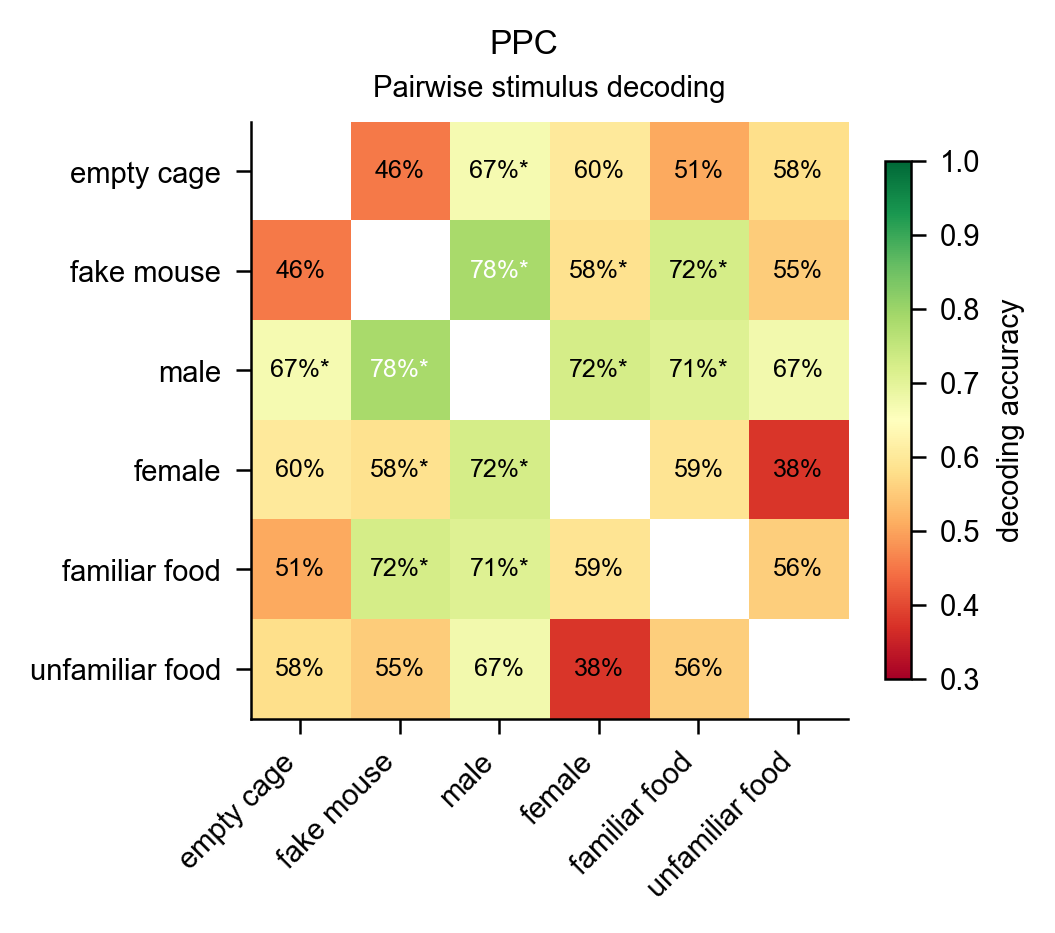

--- RL ---


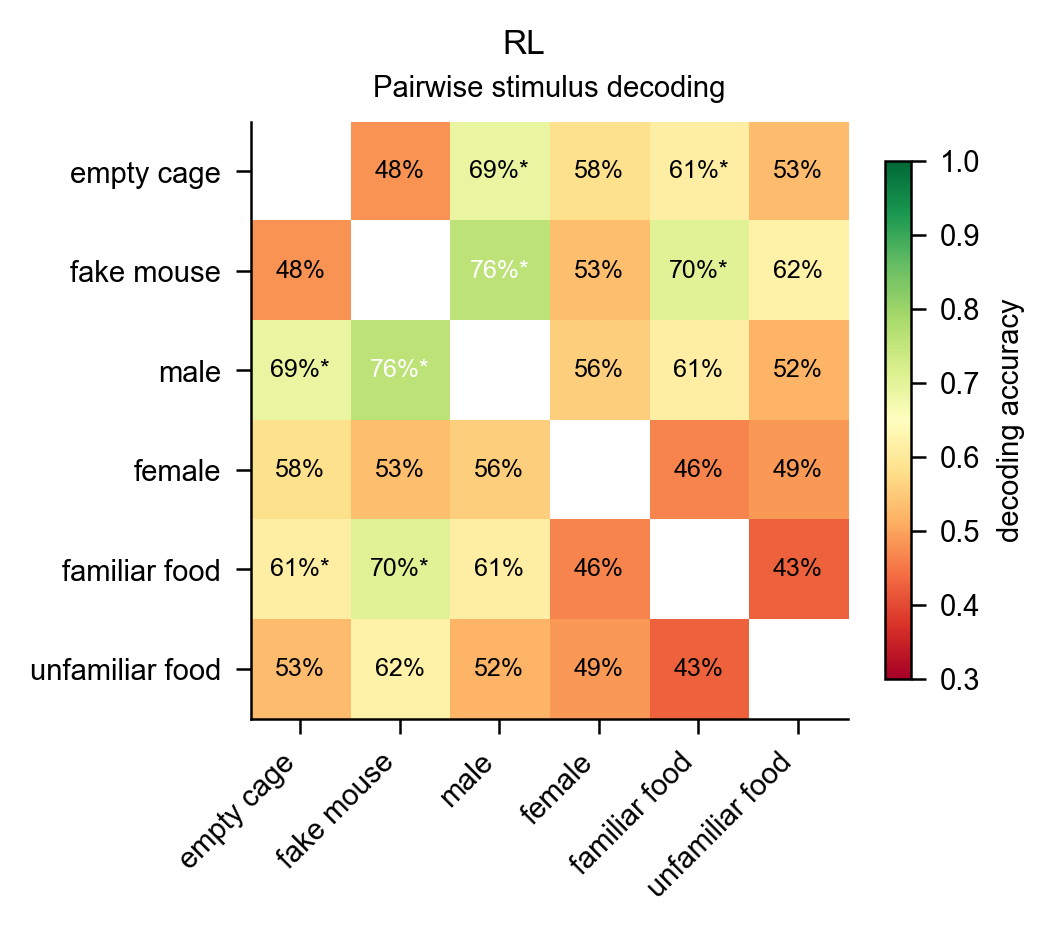

--- RSC ---


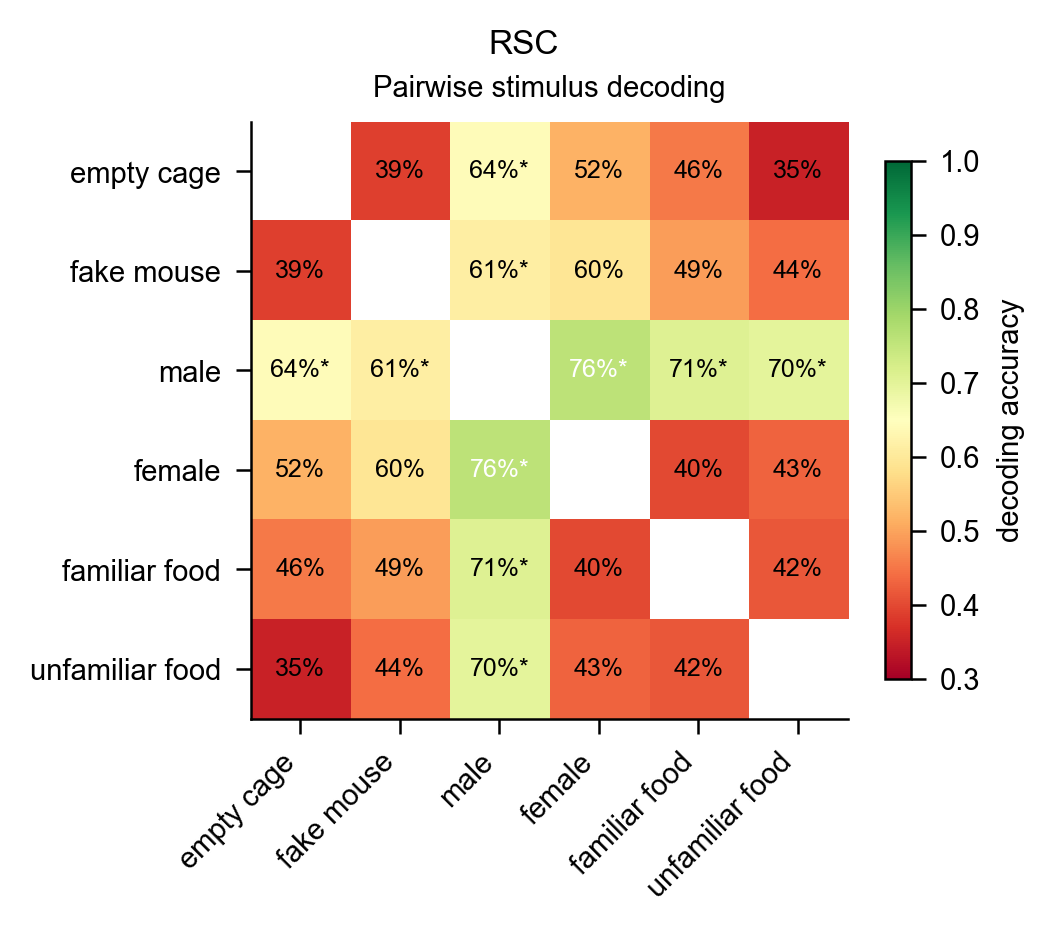

--- SMc ---


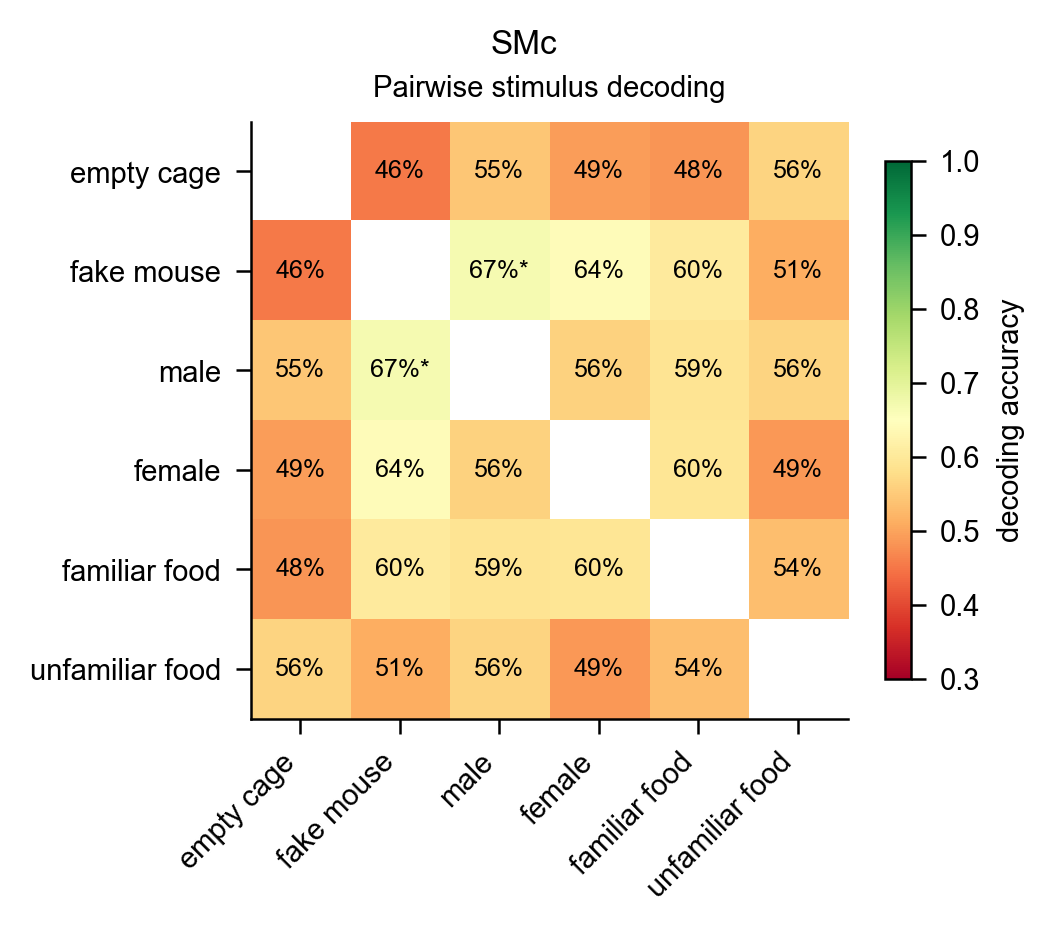

--- V1 ---


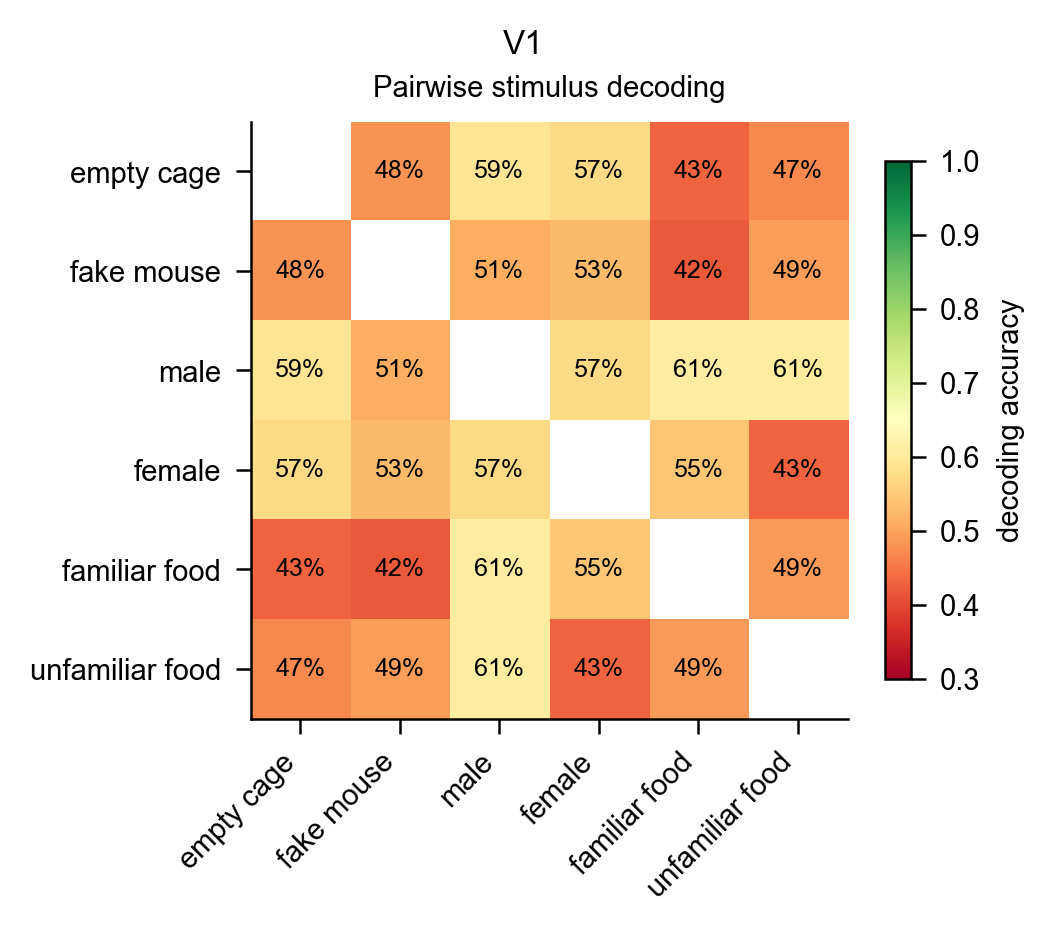

In [7]:
if na.has_regions:
    for reg in na.region_list():
        if reg.lower() == "none":
            continue
        print(f"--- {reg} ---")
        pw_reg = na.decode_pairwise(region=reg, window=(0, 6), n_shuffles=20)
        fig = na.plot_pairwise_matrix(pw_reg, dpi=300)
        fig.suptitle(reg, fontsize=8, y=1.01)
        plt.show()
else:
    print("no regions — skipping")

## Section 3b : Social vs non-social decoding by region

Group Male + Female as **social** and FamFood + NewFood as **non-social**.
Decode this binary contrast per cortical region (24 vs 24 trials).

decoding: AM
decoding: PM
decoding: PPC
decoding: RL
decoding: RSC
decoding: SMc
decoding: V1


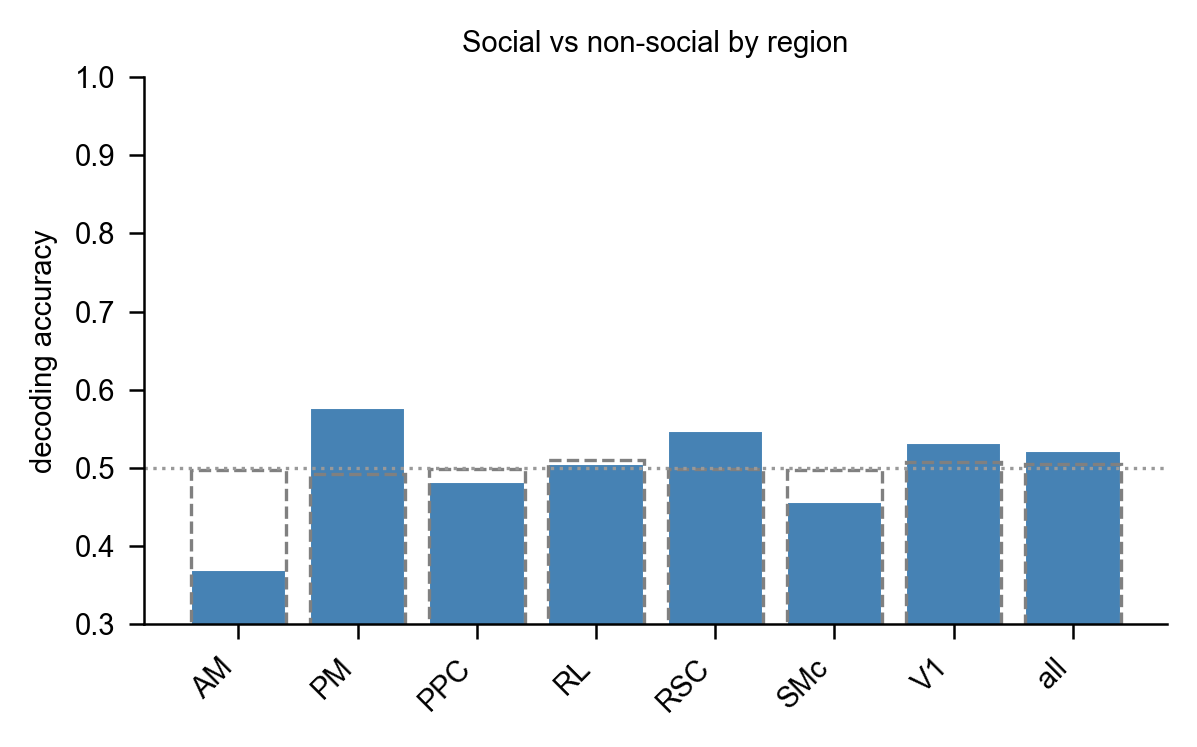

   AM  acc=36.93%  chance=49.69%  p=0.990
   PM  acc=57.73%  chance=49.18%  p=0.149
  PPC  acc=48.27%  chance=49.82%  p=0.604
   RL  acc=50.53%  chance=51.00%  p=0.564
  RSC  acc=54.80%  chance=49.82%  p=0.188
  SMc  acc=45.60%  chance=49.70%  p=0.683
   V1  acc=53.20%  chance=50.78%  p=0.426
  all  acc=52.13%  chance=50.57%  p=0.406


In [9]:
social     = ["Male", "Female"]
nonsocial  = ["FamFood", "NewFood"]

results_soc = {}
if na.has_regions:
    valid_regions = [r for r in na.region_list() if r.lower() != "none"]
    for reg in valid_regions:
        print(f"decoding: {reg}")
        r = na.decode_binary(social, nonsocial, region=reg,
                             window=(0, 4), n_shuffles=100)
        results_soc[reg] = r
    # also do all neurons
    r_all = na.decode_binary(social, nonsocial, window=(0, 4), n_shuffles=100)
    results_soc["all"] = r_all

    # bar plot
    regions_plot = valid_regions + ["all"]
    accs    = [results_soc[r]["accuracy"] for r in regions_plot]
    chances = [results_soc[r]["chance"] for r in regions_plot]
    pvals   = [results_soc[r]["p_value"] for r in regions_plot]

    fig, ax = plt.subplots(figsize=(4, 2.5), dpi=300)
    x = np.arange(len(regions_plot))
    bars = ax.bar(x, accs, color="steelblue", edgecolor="white", lw=0.5)
    ax.bar(x, chances, color="none", edgecolor="gray", lw=0.8, ls="--")
    ax.axhline(0.5, color="0.6", ls=":", lw=0.8)
    for i, p in enumerate(pvals):
        if p < 0.05:
            ax.text(i, accs[i] + 0.02, "*", ha="center", va="bottom", fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels(regions_plot, rotation=45, ha="right", fontsize=7)
    ax.set(ylabel="decoding accuracy", title="Social vs non-social by region",
           ylim=(0.3, 1.0))
    fig.tight_layout()
    plt.show()

    for reg in regions_plot:
        r = results_soc[reg]
        print(f"{reg:>5s}  acc={r['accuracy']:.2%}  chance={r['chance']:.2%}  p={r['p_value']:.3f}")
else:
    r_all = na.decode_binary(social, nonsocial, window=(0, 4), n_shuffles=100)
    print(f"all neurons  acc={r_all['accuracy']:.2%}  chance={r_all['chance']:.2%}  p={r_all['p_value']:.3f}")

## Section 4 : Raw vs kinematics-corrected pairwise decoding

Compare pairwise heatmaps before and after regressing out ball kinematics.
If accuracy drops, part of the discriminability was locomotion-mediated.

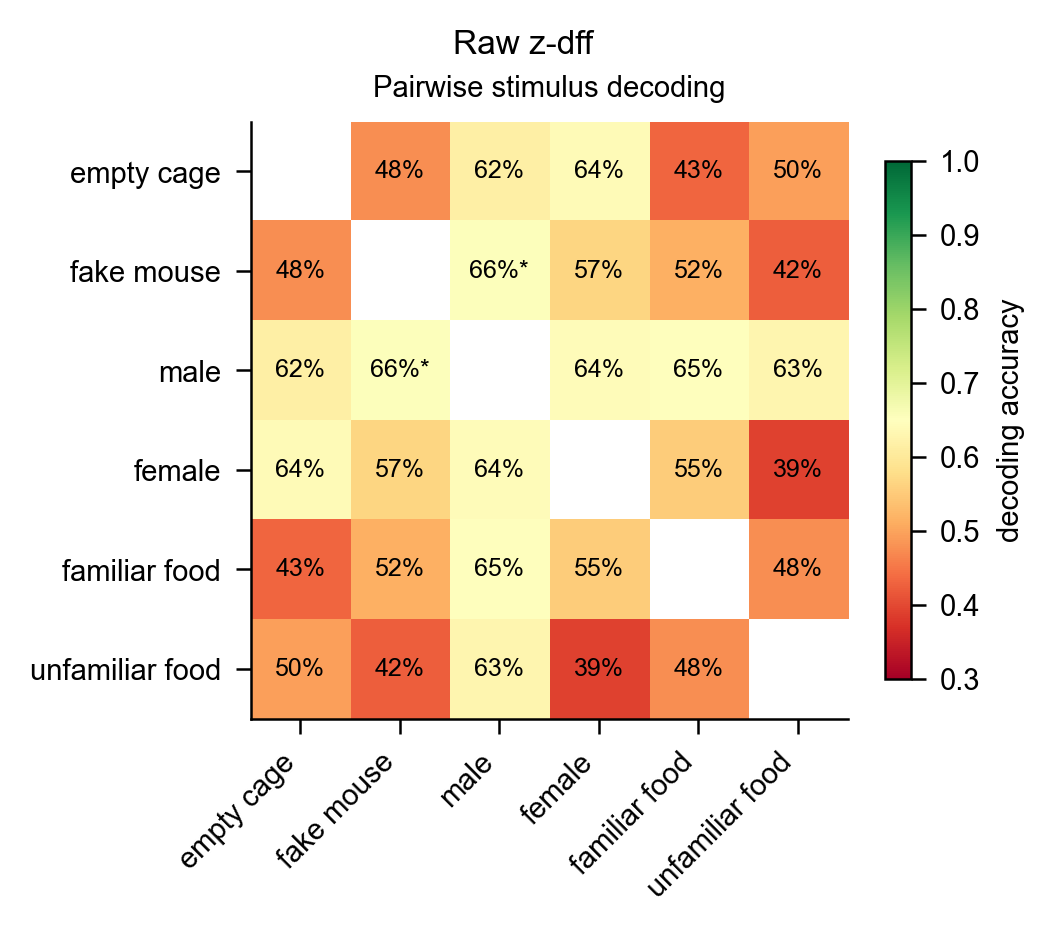

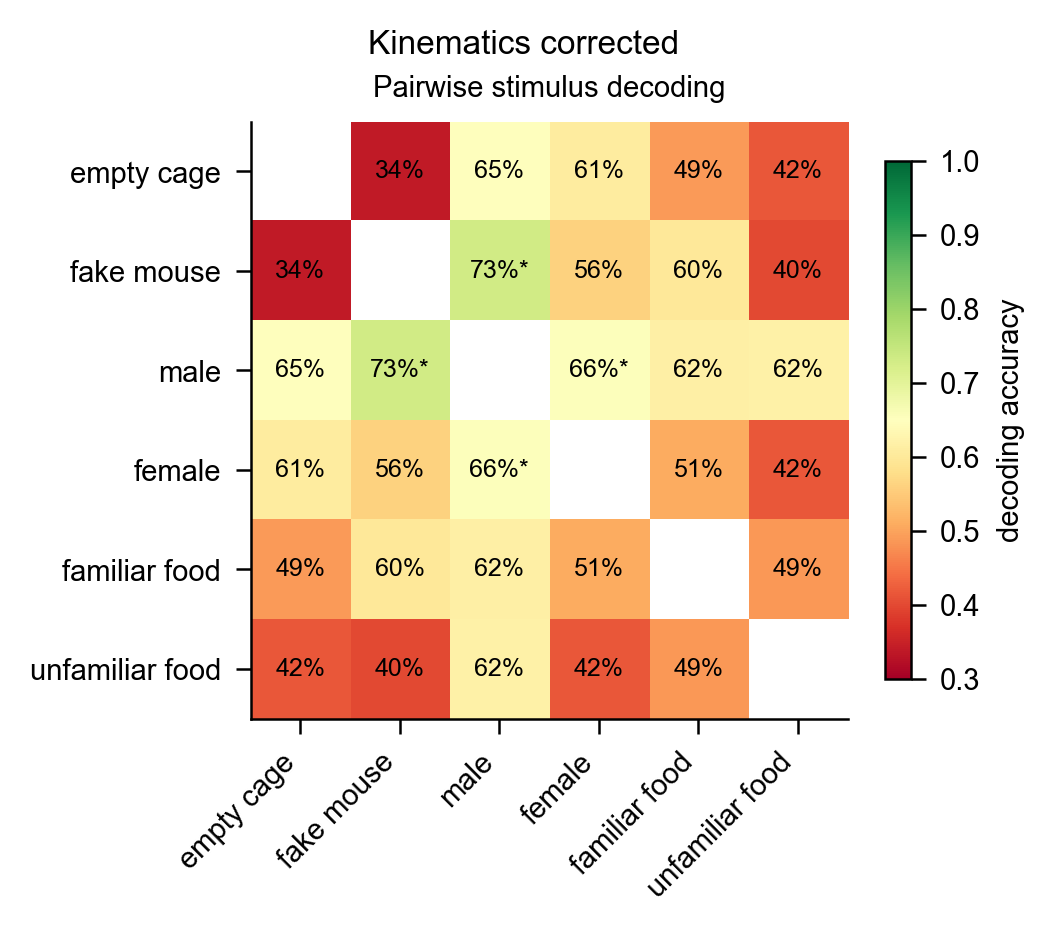

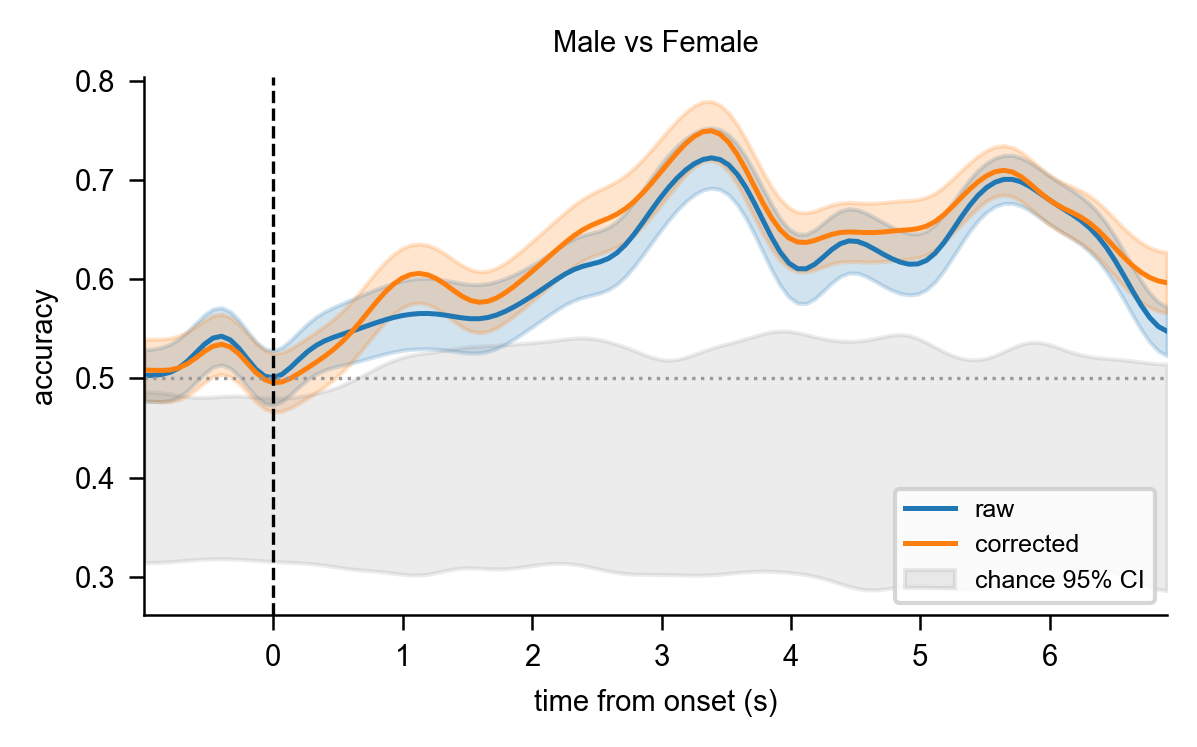

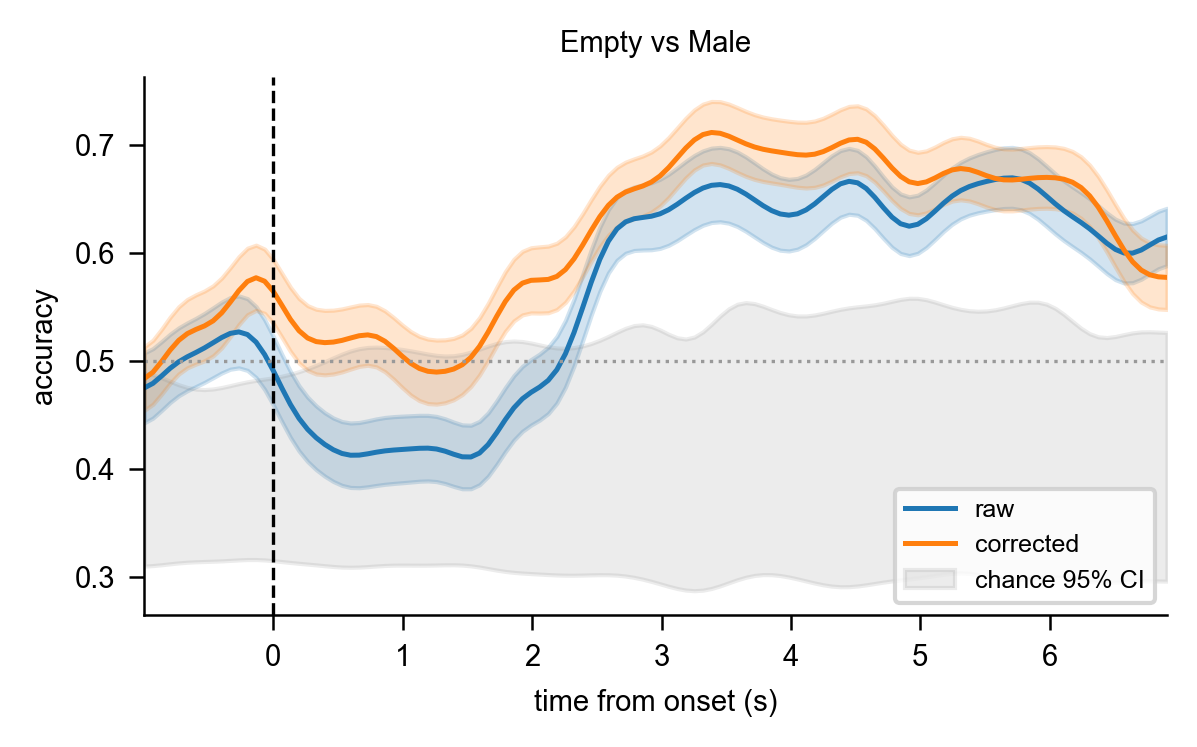

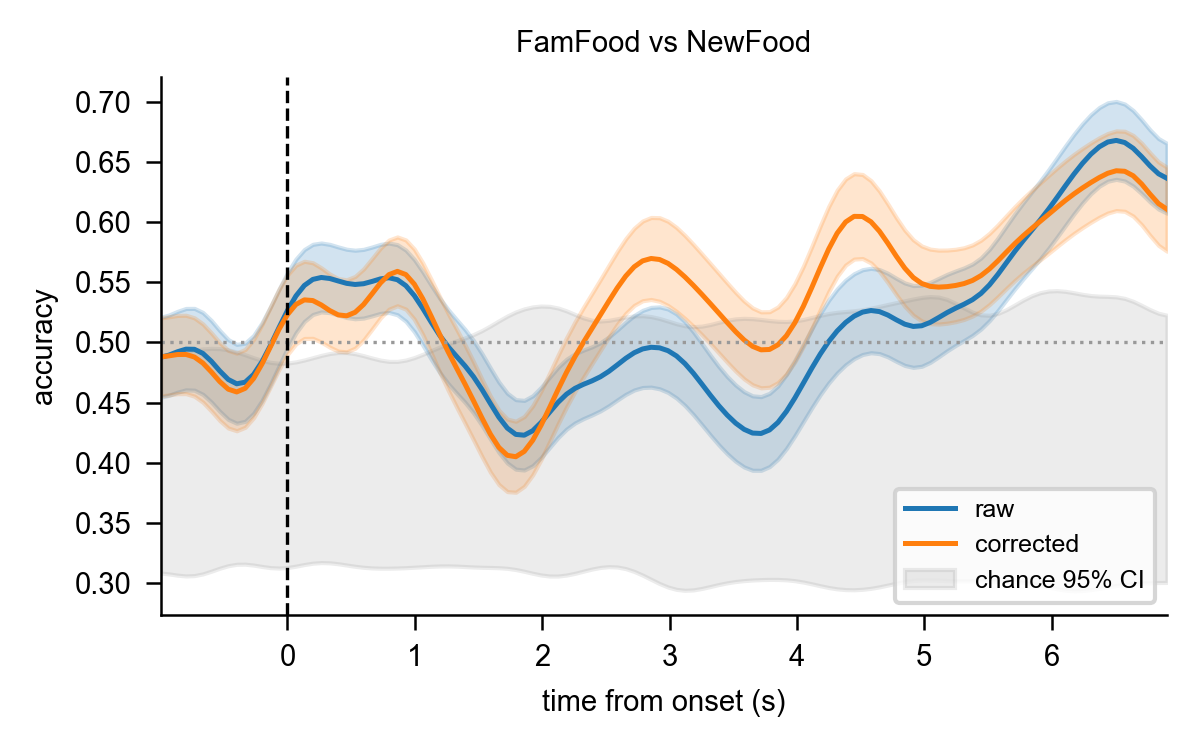

In [8]:
if X_corr is not None:
    na_corr = NeuralAnalysis(X_corr, labels, regions=regions, fs=fs, pre_frames=pre_frames)

    pw_raw  = na.decode_pairwise(window=(0, 4), n_shuffles=100)
    pw_corr = na_corr.decode_pairwise(window=(0, 4), n_shuffles=100)

    fig_raw = na.plot_pairwise_matrix(pw_raw, dpi=300)
    fig_raw.suptitle("Raw z-dff", fontsize=8, y=1.01)
    plt.show()

    fig_corr = na_corr.plot_pairwise_matrix(pw_corr, dpi=300)
    fig_corr.suptitle("Kinematics corrected", fontsize=8, y=1.01)
    plt.show()

    # temporal comparison for a few interesting pairs
    sm = lambda x: gaussian_filter1d(x, sigma=3)
    highlight_pairs = [("Male", "Female"), ("Empty", "Male"), ("FamFood", "NewFood")]
    for a, b in highlight_pairs:
        r_raw  = na.decode_temporal([a], [b], n_splits=20, n_shuffles=50, n_pcs=50)
        r_corr = na_corr.decode_temporal([a], [b], n_splits=20, n_shuffles=50, n_pcs=50)

        fig, ax = plt.subplots(figsize=(4, 2.5), dpi=300)
        t = r_raw["time"]
        ax.plot(t, sm(r_raw["accuracy"]),  lw=1.2, color="tab:blue", label="raw")
        ax.fill_between(t, sm(r_raw["accuracy"] - r_raw["accuracy_sem"]),
                           sm(r_raw["accuracy"] + r_raw["accuracy_sem"]),
                        color="tab:blue", alpha=0.2)
        ax.plot(t, sm(r_corr["accuracy"]), lw=1.2, color="tab:orange", label="corrected")
        ax.fill_between(t, sm(r_corr["accuracy"] - r_corr["accuracy_sem"]),
                           sm(r_corr["accuracy"] + r_corr["accuracy_sem"]),
                        color="tab:orange", alpha=0.2)
        ax.fill_between(t, sm(r_raw["chance_ci"][:, 0]), sm(r_raw["chance_ci"][:, 1]),
                        color="gray", alpha=0.15, label="chance 95% CI")
        ax.axhline(0.5, color="0.6", ls=":", lw=0.8)
        ax.axvline(0, color="k", ls="--", lw=0.8)
        ax.set(xlabel="time from onset (s)", ylabel="accuracy",
               title=f"{a} vs {b}", xlim=(t[0], t[-1]))
        ax.legend(fontsize=6)
        fig.tight_layout()
        plt.show()
else:
    print("no corrected tensor — run kinematics_regression.ipynb first")